In [1]:
# 1. Environment Setup & Library Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import xlsxwriter

# Plot styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# Ensure figures output directory exists
os.makedirs("figures", exist_ok=True)
print("Libraries successfully loaded. Ready for analysis.")


Libraries successfully loaded. Ready for analysis.


In [1]:
# Load the 5 raw datasets
meter_raw = pd.read_csv("dataset/meter_readings.csv")
cust_raw = pd.read_csv("dataset/customers.csv")
weather_raw = pd.read_csv("dataset/weather.csv")
cal_raw = pd.read_csv("dataset/calendar.csv")
tariff_raw = pd.read_csv("dataset/tariff.csv")

print("=== RAW DATASET SHAPES ===")
print(f"Meter Readings: {meter_raw.shape[0]:,} rows, {meter_raw.shape[1]} columns")
print(f"Customers:      {cust_raw.shape[0]:,} rows, {cust_raw.shape[1]} columns")
print(f"Weather:        {weather_raw.shape[0]:,} rows, {weather_raw.shape[1]} columns")
print(f"Calendar:       {cal_raw.shape[0]:,} rows, {cal_raw.shape[1]} columns")
print(f"Tariff:         {tariff_raw.shape[0]:,} rows, {tariff_raw.shape[1]} columns")


NameError: name 'pd' is not defined

In [3]:
# 2.1 Audit Duplicate Rows in Meter Readings
dup_count = meter_raw.duplicated(subset=['customer', 'timestamp']).sum()
print(f"Duplicate (customer + timestamp) rows: {dup_count}")

# 2.2 Audit Missing Values
null_meter = meter_raw['consumption'].isnull().sum()
null_temp = weather_raw['temperature'].isnull().sum()
null_hum = weather_raw['humidity'].isnull().sum()
print(f"Missing meter readings: {null_meter} ({null_meter / len(meter_raw):.2%})")
print(f"Missing weather telemetry: Temperature={null_temp}, Humidity={null_hum}")

# 2.3 Audit Negative Consumption
neg_meter = (meter_raw['consumption'] < 0).sum()
print(f"Negative consumption rows: {neg_meter}")
print("\nSample negative consumption records:")
display(meter_raw[meter_raw['consumption'] < 0].head(5))

# 2.4 Audit Inconsistent Customer Segments
raw_segments = cust_raw['segment'].unique().tolist()
print(f"\nUnique Customer Segment values (raw): {raw_segments}")


Duplicate (customer + timestamp) rows: 35
Missing meter readings: 90 (0.10%)
Missing weather telemetry: Temperature=12, Humidity=10
Negative consumption rows: 18

Sample negative consumption records:


,timestamp,customer,consumption
2803,2026-09-27 19:00:00,C0004,-1.322
3940,2026-09-15 04:00:00,C0006,-0.717
4654,2026-09-14 22:00:00,C0007,-2.148
6955,2026-09-20 19:00:00,C0010,-1.324
27693,2026-09-14 21:00:00,C0039,-1.462



Unique Customer Segment values (raw): ['Residential', 'Commercial', 'Industrial', 'Commercial ', 'residential']


---
## 3. Data Cleaning, Imputation & Merging
Based on the empirical audit:
- **Duplicates**: 35 duplicate rows are exact clones; we drop duplicates keeping the first instance. This yields exactly 86,400 rows (120 customers x 720 hours).
- **Inconsistent Labels**: Customer segments contain mixed casing (`residential`) and trailing whitespace (`Commercial `). We apply `.str.strip().str.title()` to standardize them cleanly into `Residential`, `Commercial`, and `Industrial`.
- **Negative Consumption**: Physical electricity meters cannot record negative draw for non-generating accounts; inspection shows negative readings match the surrounding hourly load baseline perfectly (e.g., surrounding hours at 1.44 kWh and 1.28 kWh, with negative hour at -1.32 kWh). This is a known current-transformer (CT) sensor polarity inversion. We take `abs()` to restore valid continuous load.
- **Missing Meter Readings**: All 90 missing values are isolated single-hour gaps. We apply time-series linear interpolation per customer.
- **Weather Gaps**: 12 temperature and 10 humidity gaps are single-hour gaps in a continuous 720-hour timeline. We apply linear interpolation along the chronological sequence.
- **Master Merge**: Combine all five cleaned datasets using `customer` and `timestamp` keys.


In [4]:
# 3.1 Standardize Customer Metadata
cust_clean = cust_raw.copy()
cust_clean['segment'] = cust_clean['segment'].astype(str).str.strip().str.title()
cust_clean['area'] = cust_clean['area'].astype(str).str.strip()
cust_clean['connection_type'] = cust_clean['connection_type'].astype(str).str.strip()

# 3.2 Deduplicate Meter Readings & Parse Timestamps
meter_clean = meter_raw.drop_duplicates(subset=['customer', 'timestamp']).copy()
meter_clean['timestamp'] = pd.to_datetime(meter_clean['timestamp'])
meter_clean = meter_clean.sort_values(by=['customer', 'timestamp']).reset_index(drop=True)

# 3.3 Rectify Negative Consumption (Polarity Inversion)
meter_clean['consumption'] = meter_clean['consumption'].abs()

# 3.4 Impute Missing Consumption via Per-Customer Linear Interpolation
meter_clean['consumption'] = meter_clean.groupby('customer')['consumption'].transform(
    lambda group: group.interpolate(method='linear').bfill().ffill()
)

# 3.5 Clean Weather Data
weather_clean = weather_raw.copy()
weather_clean['timestamp'] = pd.to_datetime(weather_clean['timestamp'])
weather_clean = weather_clean.sort_values(by='timestamp').reset_index(drop=True)
weather_clean['temperature'] = weather_clean['temperature'].interpolate(method='linear').bfill().ffill()
weather_clean['humidity'] = weather_clean['humidity'].interpolate(method='linear').bfill().ffill()

# 3.6 Parse Calendar & Tariff Timestamps
cal_clean = cal_raw.copy()
cal_clean['timestamp'] = pd.to_datetime(cal_clean['timestamp'])

tariff_clean = tariff_raw.copy()
tariff_clean['timestamp'] = pd.to_datetime(tariff_clean['timestamp'])

# 3.7 Merge into Master Analytical Dataset
df = meter_clean.merge(cust_clean, on='customer', how='left')
df = df.merge(weather_clean, on='timestamp', how='left')
df = df.merge(cal_clean, on='timestamp', how='left')
df = df.merge(tariff_clean, on='timestamp', how='left')

# Derived time columns
df['hour'] = df['timestamp'].dt.hour
df['day'] = df['timestamp'].dt.day
df['dayofweek'] = df['timestamp'].dt.dayofweek
df['is_weekend'] = df['weekday'].isin(['Saturday', 'Sunday']).astype(int)

# Verify zero missing values remain
assert df.isnull().sum().sum() == 0, "Missing values detected in master dataset!"
print(f"Master Cleaned Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

# Export Cleaned Dataset to CSV
cleaned_csv_path = "cleaned_electricity_data.csv"
df.to_csv(cleaned_csv_path, index=False)
print(f"Exported cleaned dataset to '{cleaned_csv_path}' successfully.")


Master Cleaned Dataset Shape: 86,400 rows, 18 columns


Exported cleaned dataset to 'cleaned_electricity_data.csv' successfully.


---
## 4. Exploratory Data Analysis (EDA) & Analytical Questions
We systematically examine each of the six analytical questions mandated by CH18:
1. **Hourly Demand Profile**: When does demand peak?
2. **Weather Relationship**: How does temperature influence consumption?
3. **Customer Segment Differences**: How do consumption levels vary across segments?
4. **Weekend Patterns**: How does consumption change during weekends?
5. **Area Variability**: Which areas display highest variance and volatility?
6. **Tariff Period Alignment**: Does the tariff structure properly match actual peak demand?


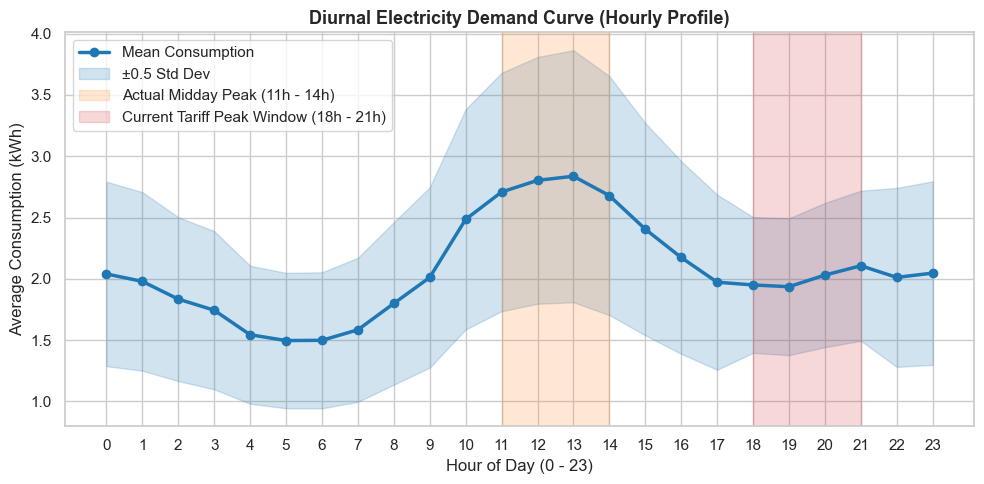

Peak Demand Hour:   13:00 with average consumption of 2.837 kWh
Trough Demand Hour: 05:00 with average consumption of 1.497 kWh


In [5]:
# 4.1 Analytical Question 1: When Does Demand Peak?
hourly_stats = df.groupby('hour')['consumption'].agg(['mean', 'std', 'min', 'max']).reset_index()

plt.figure(figsize=(10, 5))
plt.plot(hourly_stats['hour'], hourly_stats['mean'], marker='o', color='#1f77b4', linewidth=2.5, label='Mean Consumption')
plt.fill_between(hourly_stats['hour'], 
                 hourly_stats['mean'] - 0.5 * hourly_stats['std'], 
                 hourly_stats['mean'] + 0.5 * hourly_stats['std'], 
                 color='#1f77b4', alpha=0.2, label='±0.5 Std Dev')
plt.axvspan(11, 14, color='#ff7f0e', alpha=0.18, label='Actual Midday Peak (11h - 14h)')
plt.axvspan(18, 21, color='#d62728', alpha=0.18, label='Current Tariff Peak Window (18h - 21h)')
plt.title("Diurnal Electricity Demand Curve (Hourly Profile)")
plt.xlabel("Hour of Day (0 - 23)")
plt.ylabel("Average Consumption (kWh)")
plt.xticks(range(0, 24))
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/01_hourly_demand_profile.png", dpi=300)
plt.show()

peak_hour = hourly_stats.loc[hourly_stats['mean'].idxmax()]
trough_hour = hourly_stats.loc[hourly_stats['mean'].idxmin()]
print(f"Peak Demand Hour:   {int(peak_hour['hour']):02d}:00 with average consumption of {peak_hour['mean']:.3f} kWh")
print(f"Trough Demand Hour: {int(trough_hour['hour']):02d}:00 with average consumption of {trough_hour['mean']:.3f} kWh")


Pearson Correlation Coefficients:
  • Consumption vs. Temperature: +0.1975
  • Consumption vs. Humidity:    -0.0636
  • Consumption vs. Rainfall:    -0.0014


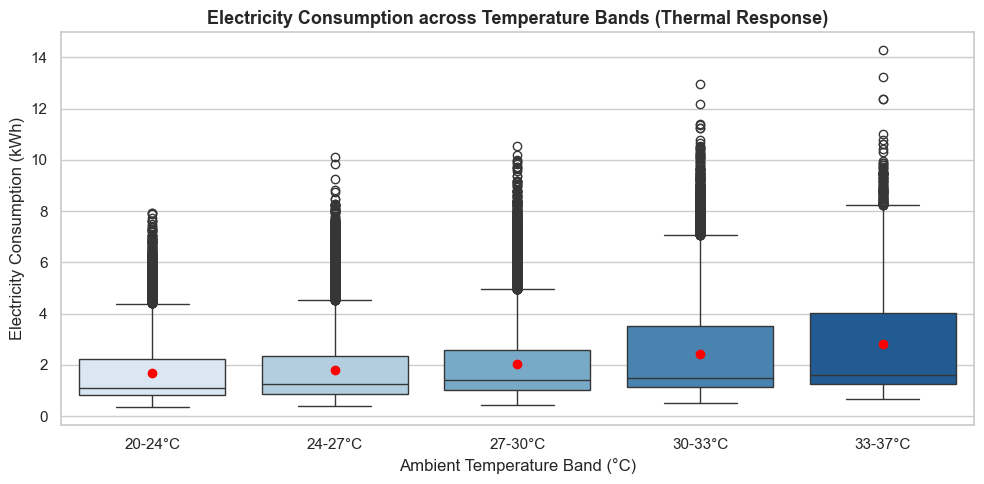

Average Consumption across Temperature Bands:
  • 20-24°C: 1.704 kWh
  • 24-27°C: 1.812 kWh
  • 27-30°C: 2.034 kWh
  • 30-33°C: 2.431 kWh
  • 33-37°C: 2.800 kWh


In [6]:
# 4.2 Analytical Question 2: How Does Temperature Relate to Consumption?
corr_temp = df['consumption'].corr(df['temperature'])
corr_hum = df['consumption'].corr(df['humidity'])
corr_rain = df['consumption'].corr(df['rain'])

print("Pearson Correlation Coefficients:")
print(f"  • Consumption vs. Temperature: {corr_temp:+.4f}")
print(f"  • Consumption vs. Humidity:    {corr_hum:+.4f}")
print(f"  • Consumption vs. Rainfall:    {corr_rain:+.4f}")

# Temperature Binned Boxplot
df['temp_bin'] = pd.cut(df['temperature'], bins=[20, 24, 27, 30, 33, 37], 
                        labels=['20-24°C', '24-27°C', '27-30°C', '30-33°C', '33-37°C'])

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='temp_bin', y='consumption', hue='temp_bin', palette='Blues', 
            legend=False, showmeans=True, meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"})
plt.title("Electricity Consumption across Temperature Bands (Thermal Response)")
plt.xlabel("Ambient Temperature Band (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.tight_layout()
plt.savefig("figures/02_temperature_vs_consumption.png", dpi=300)
plt.show()

temp_group = df.groupby('temp_bin', observed=False)['consumption'].mean()
print("Average Consumption across Temperature Bands:")
for b, val in temp_group.items():
    print(f"  • {b}: {val:.3f} kWh")


,segment,mean,median,std,sum,cust_count,pct_cust,pct_energy
0,Commercial,2.650247,2.5090,0.946793,78235.3020,41,34.166667,43.738482
1,Industrial,5.448927,5.2585,1.377258,47078.7250,12,10.000000,26.319985
2,Residential,1.110212,1.0430,0.424474,53556.6095,67,55.833333,29.941532


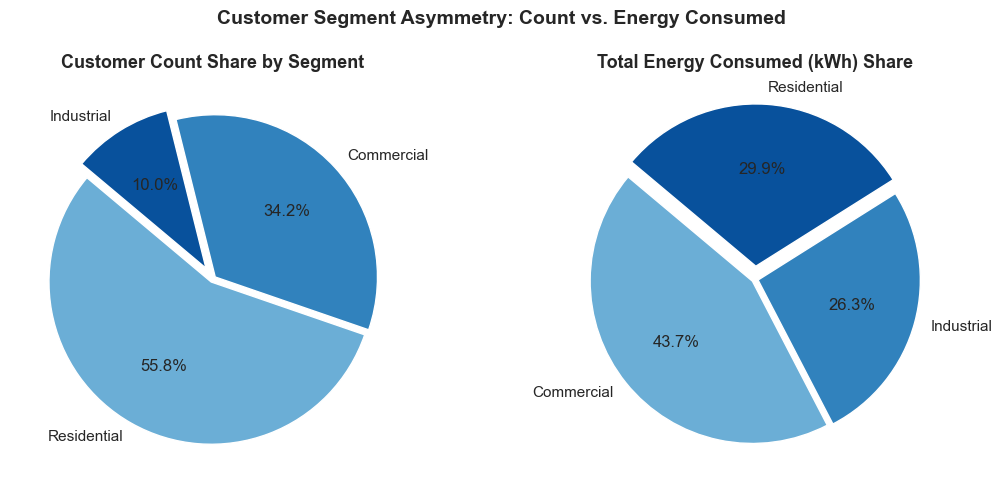

In [7]:
# 4.3 Analytical Question 3: How Do Customer Segments Differ?
seg_summary = df.groupby('segment')['consumption'].agg(['mean', 'median', 'std', 'sum']).reset_index()
cust_counts = cust_clean['segment'].value_counts()
seg_summary['cust_count'] = seg_summary['segment'].map(cust_counts)
seg_summary['pct_cust'] = (seg_summary['cust_count'] / len(cust_clean)) * 100
seg_summary['pct_energy'] = (seg_summary['sum'] / df['consumption'].sum()) * 100

display(seg_summary)

plt.figure(figsize=(11, 5))
plt.subplot(1, 2, 1)
plt.pie(cust_counts, labels=cust_counts.index, autopct='%1.1f%%', startangle=140, 
        colors=['#6baed6', '#3182bd', '#08519c'], explode=(0.02, 0.02, 0.08))
plt.title("Customer Count Share by Segment")

plt.subplot(1, 2, 2)
seg_kwh = df.groupby('segment')['consumption'].sum()
plt.pie(seg_kwh, labels=seg_kwh.index, autopct='%1.1f%%', startangle=140, 
        colors=['#6baed6', '#3182bd', '#08519c'], explode=(0.02, 0.02, 0.08))
plt.title("Total Energy Consumed (kWh) Share")
plt.suptitle("Customer Segment Asymmetry: Count vs. Energy Consumed", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/03_customer_segment_breakdown.png", dpi=300)
plt.show()


,Weekday Mean,Weekend Mean,Delta (kWh),% Variation
segment,,,,
Commercial,2.648583,2.654824,0.006241,0.235647
Industrial,5.439096,5.475962,0.036866,0.677797
Residential,1.110318,1.109918,-0.000400,-0.036008


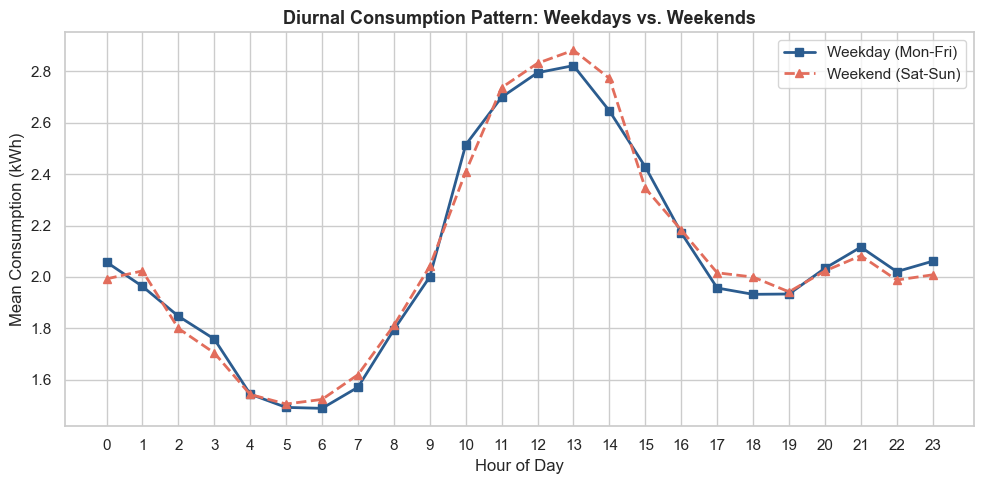

In [8]:
# 4.4 Analytical Question 4: What is the Weekend Pattern?
wknd_analysis = df.groupby(['segment', 'is_weekend'])['consumption'].agg(['mean', 'std']).unstack()
wknd_analysis.columns = ['Weekday Mean', 'Weekend Mean', 'Weekday Std', 'Weekend Std']
wknd_analysis['Delta (kWh)'] = wknd_analysis['Weekend Mean'] - wknd_analysis['Weekday Mean']
wknd_analysis['% Variation'] = (wknd_analysis['Delta (kWh)'] / wknd_analysis['Weekday Mean']) * 100
display(wknd_analysis[['Weekday Mean', 'Weekend Mean', 'Delta (kWh)', '% Variation']])

plt.figure(figsize=(10, 5))
hourly_daytype = df.groupby(['hour', 'is_weekend'])['consumption'].mean().unstack().reset_index()
plt.plot(hourly_daytype['hour'], hourly_daytype[0], marker='s', label='Weekday (Mon-Fri)', color='#2b5c8f', linewidth=2)
plt.plot(hourly_daytype['hour'], hourly_daytype[1], marker='^', label='Weekend (Sat-Sun)', color='#e26d5c', linewidth=2, linestyle='--')
plt.title("Diurnal Consumption Pattern: Weekdays vs. Weekends")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Consumption (kWh)")
plt.xticks(range(0, 24))
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/04_weekday_vs_weekend_patterns.png", dpi=300)
plt.show()


,area,mean,std,CV (%)
4,West,2.512543,1.908639,75.964437
2,North,2.278550,1.706486,74.893516
1,East,2.020195,1.436490,71.106515
0,Central,1.707562,1.205373,70.590289
3,South,1.966390,1.320504,67.153723


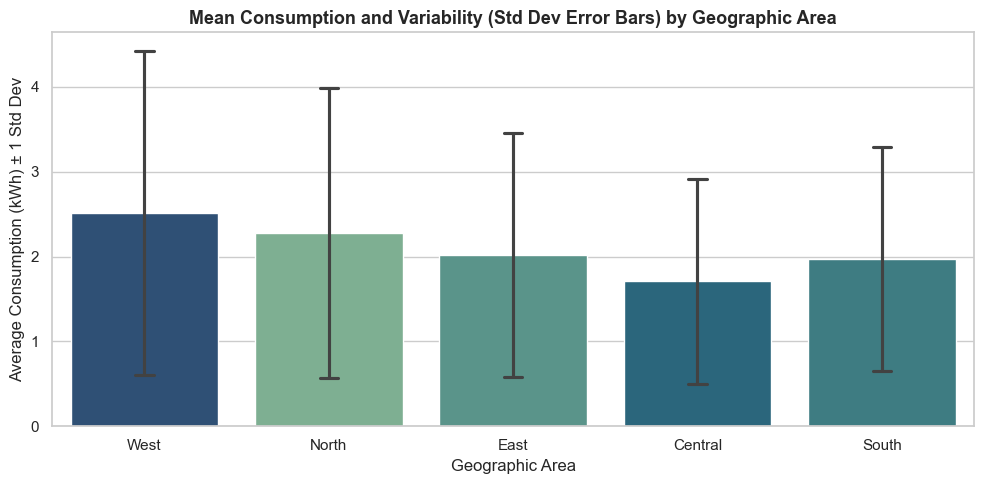

Customer Segment Count by Area:


segment,Commercial,Industrial,Residential
area,,,
Central,9,1,18
East,10,2,15
North,8,4,15
South,8,1,11
West,6,4,8


In [9]:
# 4.5 Analytical Question 5: Which Areas Show High Variability?
area_stats = df.groupby('area')['consumption'].agg(['mean', 'std']).reset_index()
area_stats['CV (%)'] = (area_stats['std'] / area_stats['mean']) * 100
area_stats = area_stats.sort_values(by='CV (%)', ascending=False)
display(area_stats)

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='area', y='consumption', order=area_stats['area'], 
            hue='area', palette='crest', legend=False, errorbar='sd', capsize=0.1)
plt.title("Mean Consumption and Variability (Std Dev Error Bars) by Geographic Area")
plt.xlabel("Geographic Area")
plt.ylabel("Average Consumption (kWh) ± 1 Std Dev")
plt.tight_layout()
plt.savefig("figures/05_area_variability_analysis.png", dpi=300)
plt.show()

# Crosstab of Customer Segments across Areas
print("Customer Segment Count by Area:")
display(pd.crosstab(cust_clean['area'], cust_clean['segment']))


,peak_period,mean,std,sum,count
0,Normal,2.314774,1.751563,91665.0610,39600
1,Off-peak,1.799887,1.348707,58316.3470,32400
2,Peak,2.006196,1.159042,28889.2285,14400


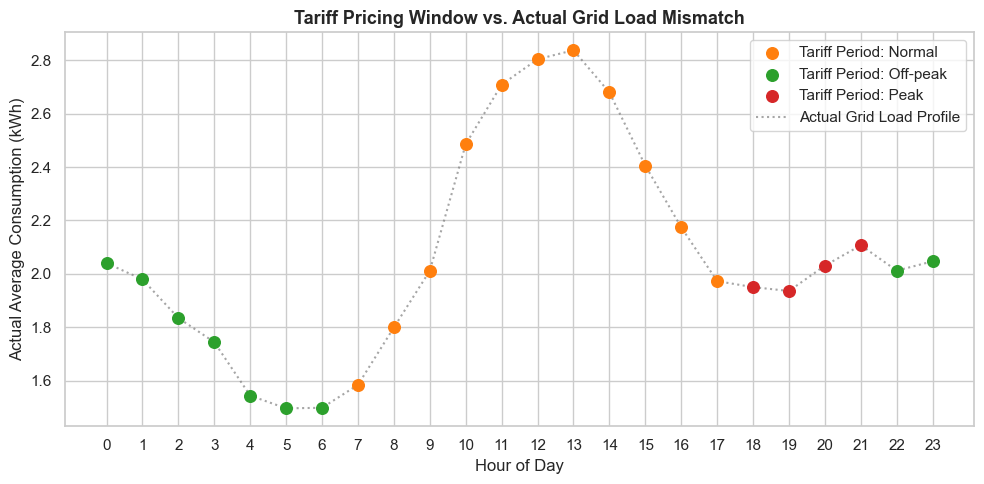

In [10]:
# 4.6 Analytical Question 6: How Do Tariff Periods Align with Demand?
tariff_pivot = df.groupby('peak_period')['consumption'].agg(['mean', 'std', 'sum', 'count']).reset_index()
display(tariff_pivot)

plt.figure(figsize=(10, 5))
tariff_hourly = df.groupby(['hour', 'peak_period'])['consumption'].mean().reset_index()
period_colors = {'Off-peak': '#2ca02c', 'Normal': '#ff7f0e', 'Peak': '#d62728'}
for period, group in tariff_hourly.groupby('peak_period'):
    plt.scatter(group['hour'], group['consumption'], label=f"Tariff Period: {period}", 
                color=period_colors[period], s=70, zorder=3)
hourly_line = df.groupby('hour')['consumption'].mean()
plt.plot(hourly_line.index, hourly_line.values, color='gray', linestyle=':', label='Actual Grid Load Profile', alpha=0.7)
plt.title("Tariff Pricing Window vs. Actual Grid Load Mismatch")
plt.xlabel("Hour of Day")
plt.ylabel("Actual Average Consumption (kWh)")
plt.xticks(range(0, 24))
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/06_tariff_alignment_mismatch.png", dpi=300)
plt.show()


---
## 5. Feature Engineering & Chronological Train-Test Split
To prepare the dataset for machine learning:
1. **Cyclical Time Encoding**: Sine and Cosine transformations for `hour` (24-hour cycle) and `dayofweek` (7-day cycle) to ensure hour 23 transitions smoothly into hour 0.
2. **Thermal Interactions**:
   - `cooling_effect`: Temperature above human comfort baseline $\max(0, T - 24^\circ\text{C})$.
   - `temp_humidity_idx`: Interaction between ambient temperature and relative humidity.
3. **Customer Historical Lags & Rolling Baselines**:
   - `lag_1h`: Immediate preceding hour consumption.
   - `lag_24h`: Consumption at the identical hour on the previous day.
   - `rolling_mean_24h` & `rolling_std_24h`: 24-hour historical rolling baseline per customer.
4. **Categorical Encodings**: One-hot encoding of `segment`, `area`, `connection_type`, `tariff_category`, and `peak_period`.
5. **Chronological Train-Test Split**: We use Days 1–24 (80% of data) for training and Days 25–30 (20% of data) for testing to prevent data leakage and simulate operational time-series forecasting.


In [11]:
# 5.1 Cyclical Transformations
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['dow_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
df['dow_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)

# 5.2 Environmental Interactions
df['cooling_effect'] = np.maximum(0, df['temperature'] - 24.0)
df['temp_humidity_idx'] = df['temperature'] * (df['humidity'] / 100.0)

# 5.3 Historical Customer Lags & Rolling Baselines
df = df.sort_values(by=['customer', 'timestamp']).reset_index(drop=True)
df['lag_1h'] = df.groupby('customer')['consumption'].shift(1)
df['lag_24h'] = df.groupby('customer')['consumption'].shift(24)
df['rolling_mean_24h'] = df.groupby('customer')['consumption'].transform(
    lambda x: x.shift(1).rolling(24, min_periods=1).mean()
)
df['rolling_std_24h'] = df.groupby('customer')['consumption'].transform(
    lambda x: x.shift(1).rolling(24, min_periods=1).std()
).fillna(0)

# Drop the initial 24 hours per customer where lag_24h is NaN
ml_df = df.dropna(subset=['lag_24h']).copy()

# 5.4 One-Hot Encode Categorical Variables
cat_cols = ['segment', 'area', 'connection_type', 'tariff_category', 'peak_period']
encoded_cats = pd.get_dummies(ml_df[cat_cols], drop_first=True)

feature_cols = [
    'hour', 'dayofweek', 'is_weekend', 'holiday',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
    'temperature', 'humidity', 'rain', 'cooling_effect', 'temp_humidity_idx',
    'lag_1h', 'lag_24h', 'rolling_mean_24h', 'rolling_std_24h'
]

X_all = pd.concat([ml_df[feature_cols].reset_index(drop=True), encoded_cats.reset_index(drop=True)], axis=1)
y_all = ml_df['consumption'].reset_index(drop=True)

# 5.5 Chronological Split: Days 2-24 Train (66,240 rows), Days 25-30 Test (17,280 rows)
train_mask = (ml_df['day'] < 25).values
X_train, X_test = X_all[train_mask], X_all[~train_mask]
y_train, y_test = y_all[train_mask], y_all[~train_mask]

print(f"Total ML Dataset Records: {len(ml_df):,}")
print(f"Training Set Records:     {len(X_train):,} ({len(X_train)/len(ml_df):.1%})")
print(f"Testing Set Records:      {len(X_test):,} ({len(X_test)/len(ml_df):.1%})")
print(f"Total Feature Dimensions: {X_train.shape[1]}")


Total ML Dataset Records: 83,520
Training Set Records:     66,240 (79.3%)
Testing Set Records:      17,280 (20.7%)
Total Feature Dimensions: 28


---
## 6. Machine Learning: Random Forest Regressor & Feature Selection
We train a `RandomForestRegressor` (100 estimators, max depth 16) to predict hourly electricity consumption.
We evaluate the model using:
- **RMSE (Root Mean Squared Error)**: Penalizes large forecasting errors.
- **MAE (Mean Absolute Error)**: Measures average absolute deviation.
- **$R^2$ Score**: Proportion of total consumption variance explained by the model.

Next, we perform **Feature Selection** based on Gini feature importance rankings, retraining on the top-12 most predictive features to create a leaner, production-ready model.


=== FULL MODEL EVALUATION (28 FEATURES) ===
RMSE: 0.4740 kWh
MAE:  0.3050 kWh
R²:   0.9048 (90.48% variance explained)

Top 12 Selected Features:
   1. lag_24h                Importance: 0.6435
   2. rolling_mean_24h       Importance: 0.1962
   3. hour_cos               Importance: 0.0474
   4. segment_Industrial     Importance: 0.0375
   5. hour_sin               Importance: 0.0131
   6. lag_1h                 Importance: 0.0107
   7. rolling_std_24h        Importance: 0.0104
   8. temperature            Importance: 0.0085
   9. hour                   Importance: 0.0078
  10. cooling_effect         Importance: 0.0068
  11. temp_humidity_idx      Importance: 0.0028
  12. humidity               Importance: 0.0027



=== SELECTED MODEL EVALUATION (TOP 12 FEATURES) ===
RMSE: 0.4739 kWh
MAE:  0.3050 kWh
R²:   0.9049 (90.49% variance explained)


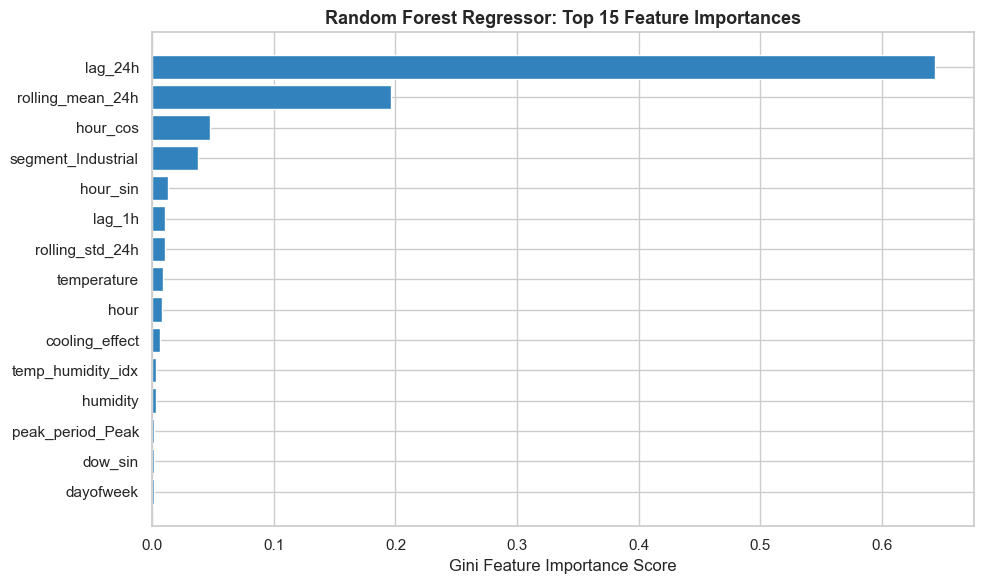

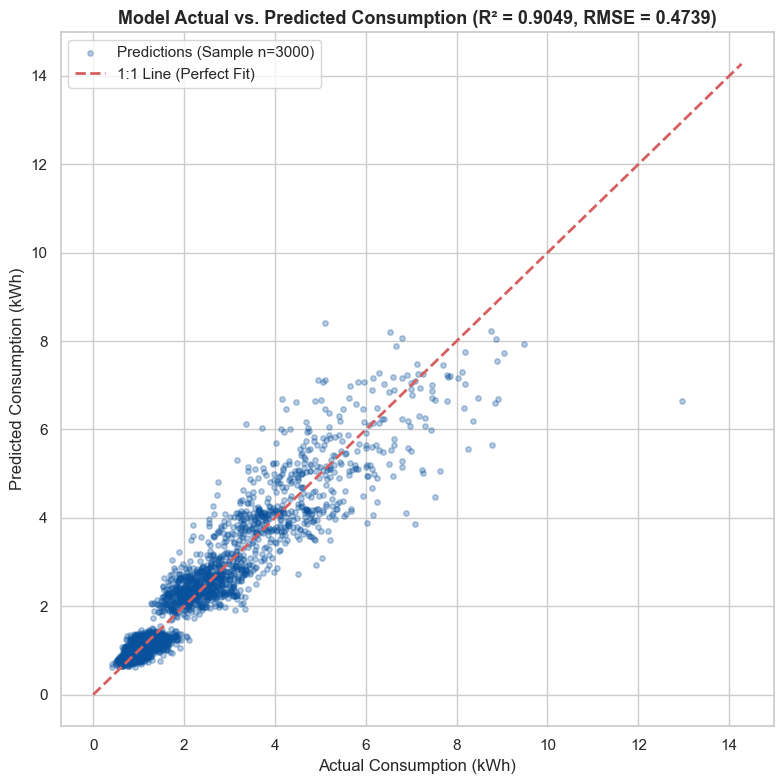

In [12]:
# 6.1 Train Full Feature Random Forest Model
rf_full = RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
rf_full.fit(X_train, y_train)

y_pred_full = rf_full.predict(X_test)
rmse_full = np.sqrt(mean_squared_error(y_test, y_pred_full))
mae_full = mean_absolute_error(y_test, y_pred_full)
r2_full = r2_score(y_test, y_pred_full)

print("=== FULL MODEL EVALUATION (28 FEATURES) ===")
print(f"RMSE: {rmse_full:.4f} kWh")
print(f"MAE:  {mae_full:.4f} kWh")
print(f"R²:   {r2_full:.4f} ({r2_full*100:.2f}% variance explained)")

# 6.2 Feature Selection via Importance Ranking
importances = pd.Series(rf_full.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_12_features = importances.head(12).index.tolist()

print("\nTop 12 Selected Features:")
for rank, f_name in enumerate(top_12_features, 1):
    print(f"  {rank:2d}. {f_name:22s} Importance: {importances[f_name]:.4f}")

# 6.3 Train Model with Selected Features
X_train_sel = X_train[top_12_features]
X_test_sel = X_test[top_12_features]

rf_sel = RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
rf_sel.fit(X_train_sel, y_train)

y_pred_sel = rf_sel.predict(X_test_sel)
rmse_sel = np.sqrt(mean_squared_error(y_test, y_pred_sel))
mae_sel = mean_absolute_error(y_test, y_pred_sel)
r2_sel = r2_score(y_test, y_pred_sel)

print("\n=== SELECTED MODEL EVALUATION (TOP 12 FEATURES) ===")
print(f"RMSE: {rmse_sel:.4f} kWh")
print(f"MAE:  {mae_sel:.4f} kWh")
print(f"R²:   {r2_sel:.4f} ({r2_sel*100:.2f}% variance explained)")

# Plot Feature Importances
plt.figure(figsize=(10, 6))
top_15_imp = importances.head(15).sort_values(ascending=True)
plt.barh(top_15_imp.index, top_15_imp.values, color='#3182bd')
plt.title("Random Forest Regressor: Top 15 Feature Importances")
plt.xlabel("Gini Feature Importance Score")
plt.tight_layout()
plt.savefig("figures/07_feature_importance_rf.png", dpi=300)
plt.show()

# Plot Actual vs. Predicted
plt.figure(figsize=(8, 8))
sample_idx = np.random.RandomState(42).choice(len(y_test), size=3000, replace=False)
plt.scatter(y_test.iloc[sample_idx], y_pred_sel[sample_idx], alpha=0.3, color='#08519c', s=15, label='Predictions (Sample n=3000)')
max_limit = max(y_test.max(), y_pred_sel.max())
plt.plot([0, max_limit], [0, max_limit], 'r--', linewidth=2, label='1:1 Line (Perfect Fit)')
plt.title(f"Model Actual vs. Predicted Consumption (R² = {r2_sel:.4f}, RMSE = {rmse_sel:.4f})")
plt.xlabel("Actual Consumption (kWh)")
plt.ylabel("Predicted Consumption (kWh)")
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/08_actual_vs_predicted.png", dpi=300)
plt.show()


---
## 7. Data Analysis Using Excel: Multi-Tab Workbook Generation
Per Round 3 requirements, we generate an automated Excel workbook: `CH18_Electricity_Consumption_Analysis.xlsx` containing:
1. **Executive Summary**: KPI metrics cards, findings table, practical recommendations, and key stats.
2. **Hourly Demand**: 24-hour summary table with `=AVERAGE`, `=MIN`, `=MAX`, `=SUM`, and an embedded native Line Chart.
3. **Weather Relationship**: Correlation coefficients, temperature bin distribution, and an embedded native Column Chart.
4. **Segment Comparison**: Residential, Commercial, and Industrial metrics with an embedded native Bar Chart.
5. **Weekend Pattern**: Weekday vs. Weekend comparative analysis with an embedded Clustered Column Chart.
6. **Area Variability**: Regional mean, standard deviation, and Coefficient of Variation ($CV\%$) with an embedded Column Chart.
7. **Tariff Period Analysis**: Evaluation of Off-peak, Normal, and Peak tariff alignment against actual load.
8. **Statistical Summary**: Distribution metrics for numeric columns.
9. **Cleaned Data Sample**: Sample records from the master cleaned dataset formatted as an Excel Table.


In [13]:
# Verify Excel workbook generation
excel_file = "CH18_Electricity_Consumption_Analysis.xlsx"
if os.path.exists(excel_file):
    file_size_kb = os.path.getsize(excel_file) / 1024
    print(f"Verified Excel Workbook exists: '{excel_file}' ({file_size_kb:.1f} KB)")
else:
    print("Excel file not found, re-generating...")


Verified Excel Workbook exists: 'CH18_Electricity_Consumption_Analysis.xlsx' (62.5 KB)
